# Bài 6.5 — Trực quan hoá luật kết hợp

Trực quan hoá các luật kết hợp tìm được ở bài trước (dữ liệu Market-Basket slide 3).

Tham khảo: http://intelligentonlinetools.com/blog/2018/02/10/how-to-create-data-visualization-for-association-rules-in-data-mining/

**Các biểu đồ:**
1. Support của từng item (nhìn dữ liệu trước khi nhìn luật)
2. Scatter `support × confidence`, màu = `lift`
3. Đồ thị luật kết hợp (network graph) — cách trình bày chính của bài blog tham khảo
4. Ma trận (heatmap) `lift` theo cặp vế trái / vế phải
5. Biểu đồ cột các luật có `lift` cao nhất
6. Bảng tra cứu đầy đủ 24 luật

In [1]:
import fim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

## 0. Bảng màu và style chung

Dùng một bảng màu thống nhất cho mọi biểu đồ:
- **Một màu xanh** cho biểu đồ một chuỗi dữ liệu (không tô mỗi cột một màu).
- **Thang một màu (light → dark)** cho đại lượng liên tục là `lift` / `confidence`.
- **Thang hai màu xanh ↔ đỏ, giữa là xám** cho `lift` vì nó có mốc trung tính rõ ràng: `lift = 1` nghĩa là hai vế độc lập, `> 1` là hút nhau, `< 1` là đẩy nhau.
- Lưới và trục là nét mảnh, chìm; chữ dùng màu mực chứ không dùng màu của chuỗi dữ liệu.

In [2]:
SURFACE = "#fcfcfb"   # nền
INK     = "#0b0b0b"   # chữ chính
INK2    = "#52514e"   # chữ phụ
MUTED   = "#898781"   # nhãn trục
GRID    = "#e1e0d9"   # lưới
AXIS    = "#c3c2b7"   # trục
BLUE    = "#2a78d6"   # màu chuỗi dữ liệu chính
ORANGE  = "#eb6834"   # màu phân loại thứ hai

# thang một màu (magnitude) và thang hai màu (lift quanh mốc 1)
SEQ = LinearSegmentedColormap.from_list(
    "seq", ["#86b6ef", "#5598e7", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(
    "div", ["#104281", "#2a78d6", "#9ec5f4", "#f0efec", "#f0a9a8", "#e34948", "#a32b2b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "font.size": 10, "figure.dpi": 110,
})

def style_colorbar(cb, label):
    cb.set_label(label, color=INK2)
    cb.outline.set_visible(False)
    cb.ax.tick_params(color=MUTED, labelcolor=MUTED)

## 1. Dữ liệu và các luật (lấy lại từ bài trước)

In [3]:
transactions = {
    1: ["Bread", "Milk"],
    2: ["Bread", "Diaper", "Beer", "Eggs"],
    3: ["Milk", "Diaper", "Beer", "Coke"],
    4: ["Bread", "Milk", "Diaper", "Beer"],
    5: ["Bread", "Milk", "Diaper", "Coke"],
}
tracts = list(transactions.values())
N = len(tracts)

MIN_SUP_PCT, MIN_CONF_PCT = 40, 60

raw = fim.apriori(tracts, target='r', supp=MIN_SUP_PCT, conf=MIN_CONF_PCT, zmin=2, report='aSCl')

rules = pd.DataFrame([
    {"antecedent": tuple(sorted(body)), "consequent": head, "count": cnt,
     "support": sup / 100, "confidence": conf / 100, "lift": lift}
    for head, body, cnt, sup, conf, lift in raw
])
rules["ante_label"] = rules["antecedent"].map(lambda a: ", ".join(a))
rules["rule"] = "{" + rules["ante_label"] + "} => {" + rules["consequent"] + "}"
rules = rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)

print(f"{len(rules)} luật (minSup {MIN_SUP_PCT}%, minConf {MIN_CONF_PCT}%)")
rules[["rule", "support", "confidence", "lift"]].head()

24 luật (minSup 40%, minConf 60%)


,rule,support,confidence,lift
0,"{Diaper, Milk} => {Coke}",0.4,0.666667,1.666667
1,"{Coke, Milk} => {Diaper}",0.4,1.000000,1.250000
2,"{Coke, Diaper} => {Milk}",0.4,1.000000,1.250000
3,{Coke} => {Milk},0.4,1.000000,1.250000
4,{Coke} => {Diaper},0.4,1.000000,1.250000


## 2. Support của từng item

Trước khi xem luật, nhìn xem item nào phổ biến. Một chuỗi dữ liệu → **một màu duy nhất**; giá trị ghi ngay đầu cột nên không cần trục x dày đặc.

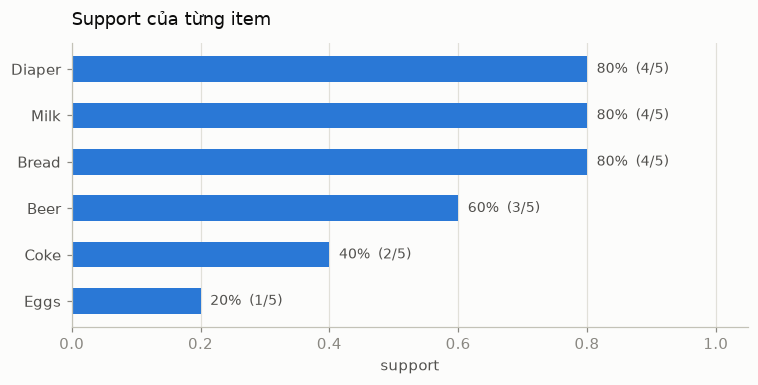

In [4]:
item_sets = fim.apriori(tracts, target='s', supp=0, zmax=1, report='aS')
items = (pd.DataFrame([{"item": s[0], "count": c, "support": p / 100} for s, c, p in item_sets])
         .sort_values("support"))

fig, ax = plt.subplots(figsize=(7.0, 3.6))
bars = ax.barh(items["item"], items["support"], height=0.55, color=BLUE)
for b, (c, s) in zip(bars, zip(items["count"], items["support"])):
    ax.text(s + 0.015, b.get_y() + b.get_height() / 2, f"{s:.0%}  ({c}/{N})",
            va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 1.05)
ax.set_xlabel("support")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelcolor=INK2, labelsize=10)
ax.set_title("Support của từng item", color=INK, fontsize=11.5, loc="left", pad=12)
plt.tight_layout(); plt.show()

## 3. Scatter `support × confidence`, màu theo `lift`

Đây là biểu đồ kinh điển để chọn luật: góc **trên bên phải** là luật vừa phổ biến vừa đáng tin.

Vì CSDL chỉ có 5 giao dịch nên nhiều luật rơi đúng vào cùng một toạ độ — thêm một lượng nhiễu (jitter) rất nhỏ để tách các điểm chồng nhau; giá trị thật vẫn nằm trong bảng ở mục 6.

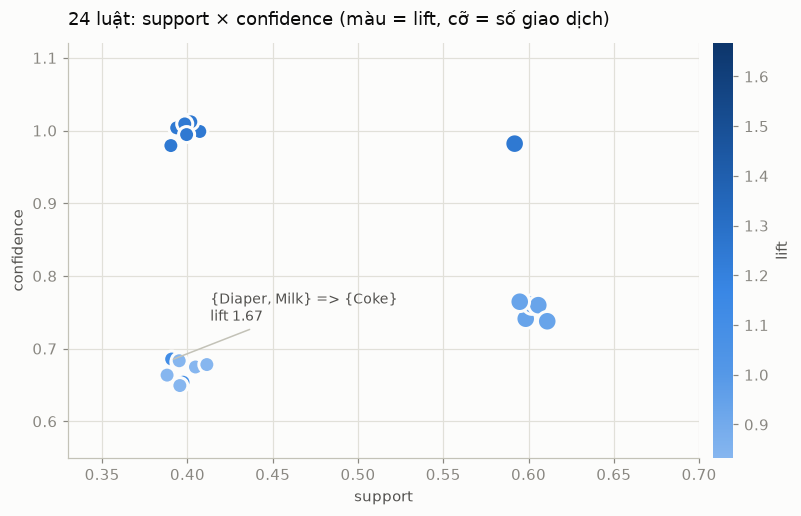

In [5]:
rng = np.random.default_rng(3)
jx = rules["support"]   + rng.uniform(-0.012, 0.012, len(rules))
jy = rules["confidence"] + rng.uniform(-0.022, 0.022, len(rules))

fig, ax = plt.subplots(figsize=(7.4, 4.8))
sc = ax.scatter(jx, jy, s=rules["count"] * 55, c=rules["lift"], cmap=SEQ,
                edgecolors=SURFACE, linewidths=2, zorder=3)
style_colorbar(fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.045), "lift")

top = rules.iloc[0]
ax.annotate(f"{top['rule']}\nlift {top['lift']:.2f}", (jx[0], jy[0]),
            textcoords="offset points", xytext=(26, 26), fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle="-", color=AXIS, lw=1))

ax.set_xlabel("support"); ax.set_ylabel("confidence")
ax.set_xlim(0.33, 0.70); ax.set_ylim(0.55, 1.12)
ax.set_title(f"{len(rules)} luật: support × confidence (màu = lift, cỡ = số giao dịch)",
             color=INK, fontsize=11.5, loc="left", pad=12)
plt.tight_layout(); plt.show()

## 4. Đồ thị luật kết hợp (network graph)

Cách trình bày trong bài blog tham khảo: mỗi luật là một **mũi tên** đi từ vế trái sang vế phải.

- Chấm **xanh** bên trái = vế trái (antecedent), chấm **cam** bên phải = vế phải (consequent) — hai vai trò khác nhau nên dùng hai màu phân loại, có chú thích kèm nhãn chữ.
- **Màu mũi tên** = `lift`, **độ dày mũi tên** = `confidence`.
- Chỉ vẽ 10 luật `lift` cao nhất; vẽ cả 24 luật sẽ rối không đọc được.

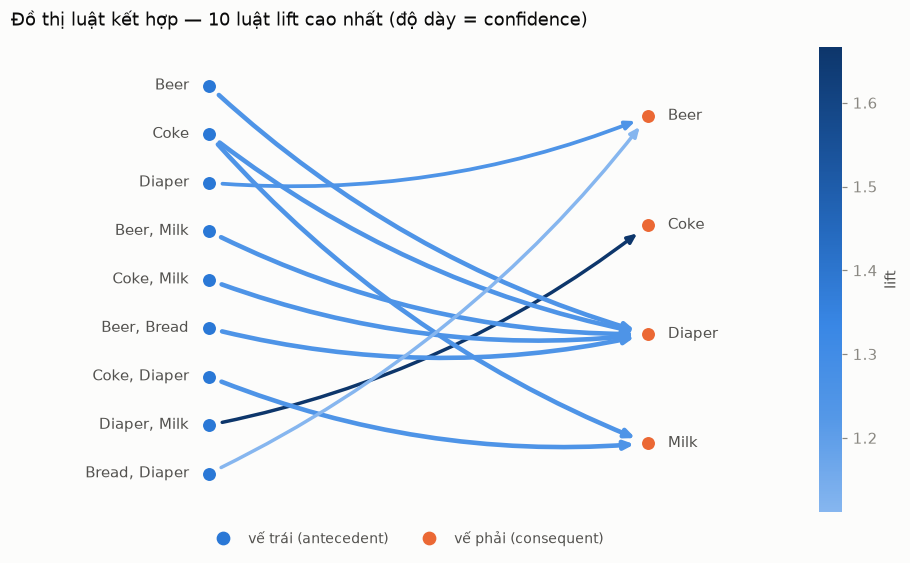

In [6]:
TOP_N = 10
top10 = rules.head(TOP_N)

lefts  = sorted({a for a in top10["ante_label"]}, key=lambda s: (len(s), s))
rights = sorted(set(top10["consequent"]))

def column_pos(names, x, total):
    """Rải đều các node của một cột theo chiều dọc."""
    n = len(names)
    return {name: (x, (total - 1) / 2 - (i - (n - 1) / 2) * (total / n))
            for i, name in enumerate(names)}

total = max(len(lefts), len(rights))
pos = {("L", k): v for k, v in column_pos(lefts, 0.0, total).items()}
pos.update({("R", k): v for k, v in column_pos(rights, 1.0, total).items()})

fig, ax = plt.subplots(figsize=(8.4, 5.2))
norm = Normalize(vmin=top10["lift"].min(), vmax=top10["lift"].max())

for _, r in top10.iterrows():
    x1, y1 = pos[("L", r["ante_label"])]
    x2, y2 = pos[("R", r["consequent"])]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>,head_length=0.5,head_width=0.22",
                                color=SEQ(norm(r["lift"])),
                                lw=0.8 + 2.2 * r["confidence"],
                                shrinkA=9, shrinkB=9,
                                connectionstyle="arc3,rad=0.12"))

for (side, label), (x, y) in pos.items():
    ax.scatter([x], [y], s=110, color=BLUE if side == "L" else ORANGE,
               edgecolors=SURFACE, linewidths=2, zorder=3)
    ax.text(x - 0.045 if side == "L" else x + 0.045, y, label,
            ha="right" if side == "L" else "left", va="center", fontsize=9.5, color=INK2)

style_colorbar(fig.colorbar(ScalarMappable(norm=norm, cmap=SEQ), ax=ax, pad=0.02, fraction=0.035), "lift")
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=BLUE,   label='vế trái (antecedent)',  markersize=8),
                   Line2D([], [], marker='o', ls='', color=ORANGE, label='vế phải (consequent)', markersize=8)],
          loc="lower center", bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=False,
          fontsize=9, labelcolor=INK2)
ax.set_xlim(-0.45, 1.35); ax.set_ylim(-0.8, total - 0.2); ax.axis("off")
ax.set_title(f"Đồ thị luật kết hợp — {TOP_N} luật lift cao nhất (độ dày = confidence)",
             color=INK, fontsize=11.5, loc="left", pad=14)
plt.tight_layout(); plt.show()

## 5. Ma trận `lift` (heatmap)

Mỗi ô là một luật: hàng = vế trái, cột = vế phải. Ô trắng = cặp đó không tạo thành luật nào vượt ngưỡng.

Thang màu **phân kỳ** lấy `lift = 1` (xám) làm mốc: xanh = `lift < 1` (hai vế đẩy nhau), đỏ = `lift > 1` (hai vế hút nhau). Giá trị ghi thẳng trong ô nên màu chỉ đóng vai trò hỗ trợ.

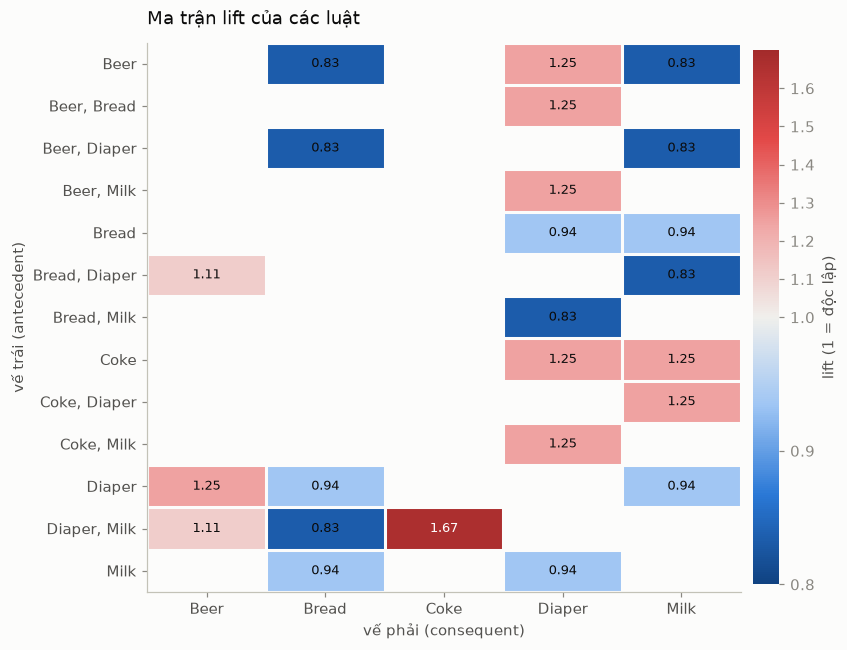

In [7]:
piv = rules.pivot_table(index="ante_label", columns="consequent", values="lift")

fig, ax = plt.subplots(figsize=(7.6, 5.8), layout="constrained")
im = ax.imshow(piv.values, cmap=DIV, norm=TwoSlopeNorm(vmin=0.8, vcenter=1.0, vmax=1.7), aspect="auto")

ax.set_xticks(range(len(piv.columns)), piv.columns, fontsize=9.5)
ax.set_yticks(range(len(piv.index)), piv.index, fontsize=9.5)
ax.tick_params(labelcolor=INK2)
ax.grid(False)

# khe hở 2px giữa các ô, vẽ bằng chính màu nền
ax.set_xticks(np.arange(-0.5, len(piv.columns)), minor=True)
ax.set_yticks(np.arange(-0.5, len(piv.index)), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)

for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if abs(v - 1) > 0.25 else INK)

style_colorbar(fig.colorbar(im, ax=ax, pad=0.02, fraction=0.045), "lift (1 = độc lập)")
ax.set_xlabel("vế phải (consequent)"); ax.set_ylabel("vế trái (antecedent)")
ax.set_title("Ma trận lift của các luật", color=INK, fontsize=11.5, loc="left", pad=12)
plt.show()

## 6. Các luật có `lift` cao nhất

Làm nổi bật điều cần nói: luật có `lift < 1` (xám) thực ra **không đáng quan tâm** dù confidence cao, vì chúng chỉ phản ánh việc item vế phải vốn đã rất phổ biến.

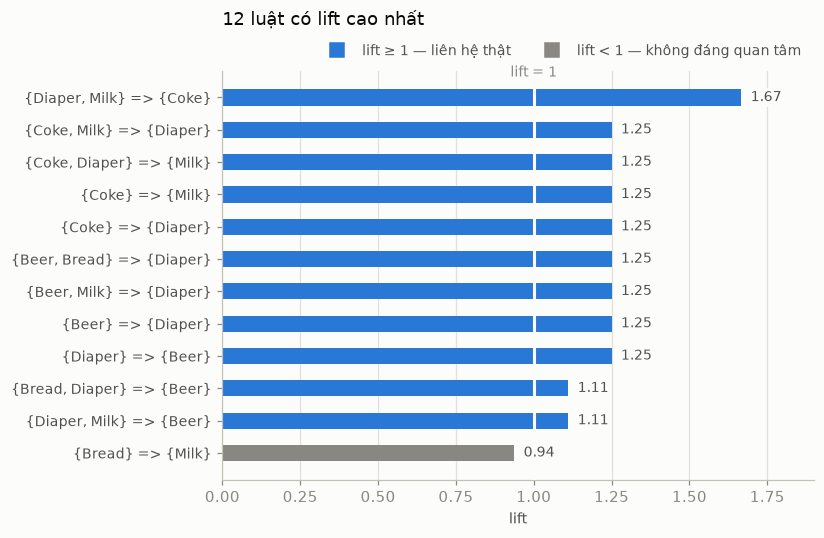

In [8]:
top12 = rules.head(12).iloc[::-1]
colors = [BLUE if l >= 1 else MUTED for l in top12["lift"]]

fig, ax = plt.subplots(figsize=(7.6, 5.0))
bars = ax.barh(top12["rule"], top12["lift"], height=0.5, color=colors, zorder=2)
for b, v in zip(bars, top12["lift"]):
    ax.text(v + 0.03, b.get_y() + b.get_height() / 2, f"{v:.2f}",
            va="center", fontsize=9, color=INK2,
            zorder=5, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))

ax.axvline(1, color=SURFACE, lw=2, zorder=3)          # mốc lift = 1
ax.text(1, len(top12) - 0.35, "lift = 1", fontsize=9, color=MUTED, ha="center")

ax.set_xlim(0, 1.9); ax.set_xlabel("lift")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=9, labelcolor=INK2)
ax.legend(handles=[Line2D([], [], marker='s', ls='', color=BLUE,  label='lift ≥ 1 — liên hệ thật', markersize=9),
                   Line2D([], [], marker='s', ls='', color=MUTED, label='lift < 1 — không đáng quan tâm', markersize=9)],
          loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2,
          frameon=False, fontsize=9, labelcolor=INK2)
ax.set_title("12 luật có lift cao nhất", color=INK, fontsize=11.5, loc="left", pad=30)
plt.tight_layout(); plt.show()

## 7. Bảng tra cứu đầy đủ

Biểu đồ để nhìn nhanh, bảng để tra giá trị chính xác.

In [9]:
table = rules[["rule", "count", "support", "confidence", "lift"]].copy()
table.columns = ["Luật", "Số giao dịch", "Support", "Confidence", "Lift"]
table.index = range(1, len(table) + 1)

(table.style
      .format({"Support": "{:.2f}", "Confidence": "{:.2f}", "Lift": "{:.2f}"})
      .background_gradient(subset=["Lift"], cmap=DIV, vmin=0.8, vmax=1.7)
      .set_caption(f"{len(table)} luật kết hợp — minSup {MIN_SUP_PCT}%, minConf {MIN_CONF_PCT}%"))

,Luật,Số giao dịch,Support,Confidence,Lift
1,"{Diaper, Milk} => {Coke}",2,0.40,0.67,1.67
2,"{Coke, Milk} => {Diaper}",2,0.40,1.00,1.25
3,"{Coke, Diaper} => {Milk}",2,0.40,1.00,1.25
4,{Coke} => {Milk},2,0.40,1.00,1.25
5,{Coke} => {Diaper},2,0.40,1.00,1.25
6,"{Beer, Bread} => {Diaper}",2,0.40,1.00,1.25
7,"{Beer, Milk} => {Diaper}",2,0.40,1.00,1.25
8,{Beer} => {Diaper},3,0.60,1.00,1.25
9,{Diaper} => {Beer},3,0.60,0.75,1.25
10,"{Bread, Diaper} => {Beer}",2,0.40,0.67,1.11


## 8. Nhận xét

- **Scatter** cho thấy các luật gom thành 4 cụm rõ rệt: `support` chỉ nhận 2 giá trị (0.4 và 0.6) và `confidence` chỉ nhận 3 giá trị (0.67 / 0.75 / 1.0) — hệ quả của việc CSDL chỉ có 5 giao dịch.
- **Đồ thị luật** cho thấy `Diaper` là item "hút" mạnh nhất: rất nhiều mũi tên đổ về nó. Đây chính là luật *bia – tã* kinh điển: `{Beer} => {Diaper}` với confidence 100%.
- **Heatmap** làm lộ điều mà confidence che giấu: nhiều luật có confidence 0.75 nhưng `lift = 0.94 < 1`, tức vế trái và vế phải **không** hỗ trợ nhau — chúng "đúng" chỉ vì `Bread`, `Milk`, `Diaper` vốn đã xuất hiện ở 80% giao dịch.
- Luật đáng giá nhất là `{Diaper, Milk} => {Coke}` với `lift = 1.67`, cao hơn hẳn phần còn lại.
- Lưu ý khi đọc: với CSDL 5 giao dịch, mọi kết luận chỉ mang tính minh hoạ — `support = 0.4` chỉ tương ứng với **2 giao dịch**.